# Challenge 1: Predict the Output

This notebook tests one X gate, two X gates, and one H gate. Each circuit is measured for 100 shots.

**Predictions:** one X should give `1`; two X gates should return `0`; H should give approximately equal numbers of `0` and `1`.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

SHOTS = 100


Circuit A: one X gate


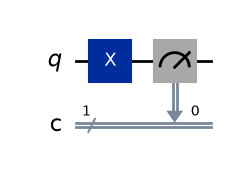

Counts: {'1': 100}
Circuit B: two X gates


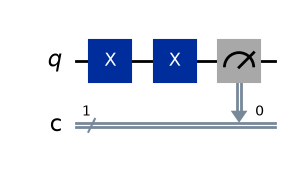

Counts: {'0': 100}
Circuit C: one H gate


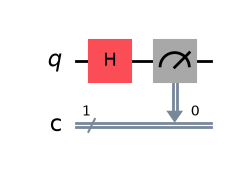

Counts: {'1': 40, '0': 60}


In [2]:
def run_case(name, gates):
    circuit = QuantumCircuit(1, 1)
    for gate in gates:
        getattr(circuit, gate)(0)
    circuit.measure(0, 0)
    counts = StatevectorSampler().run([circuit], shots=SHOTS).result()[0].data.c.get_counts()
    print(name)
    display(circuit.draw(output="mpl"))
    print("Counts:", counts)
    return counts

counts_a = run_case("Circuit A: one X gate", ["x"])
counts_b = run_case("Circuit B: two X gates", ["x", "x"])
counts_c = run_case("Circuit C: one H gate", ["h"])


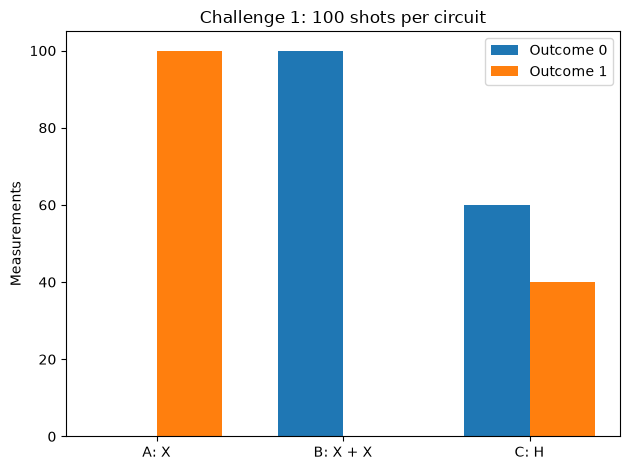

In [3]:
fig, ax = plt.subplots()
labels = ["A: X", "B: X + X", "C: H"]
for i, outcome in enumerate(["0", "1"]):
    ax.bar([j + (i - 0.5) * 0.35 for j in range(3)],
           [counts.get(outcome, 0) for counts in [counts_a, counts_b, counts_c]],
           width=0.35, label=f"Outcome {outcome}")
ax.set_xticks(range(3), labels)
ax.set_ylabel("Measurements")
ax.set_title("Challenge 1: 100 shots per circuit")
ax.legend()
plt.tight_layout()
plt.show()


## Comparison

The X gate flips `|0⟩` and `|1⟩`. Applying X twice returns the qubit to its starting state. The H gate creates an equal superposition, so its measurements vary from run to run and should be close to 50/50 over 100 shots.
